<a href="https://colab.research.google.com/github/ichaxpro/PCVK_2026/blob/main/Week2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Pertanyaan Praktikum

Displaying image using cv2_imshow():


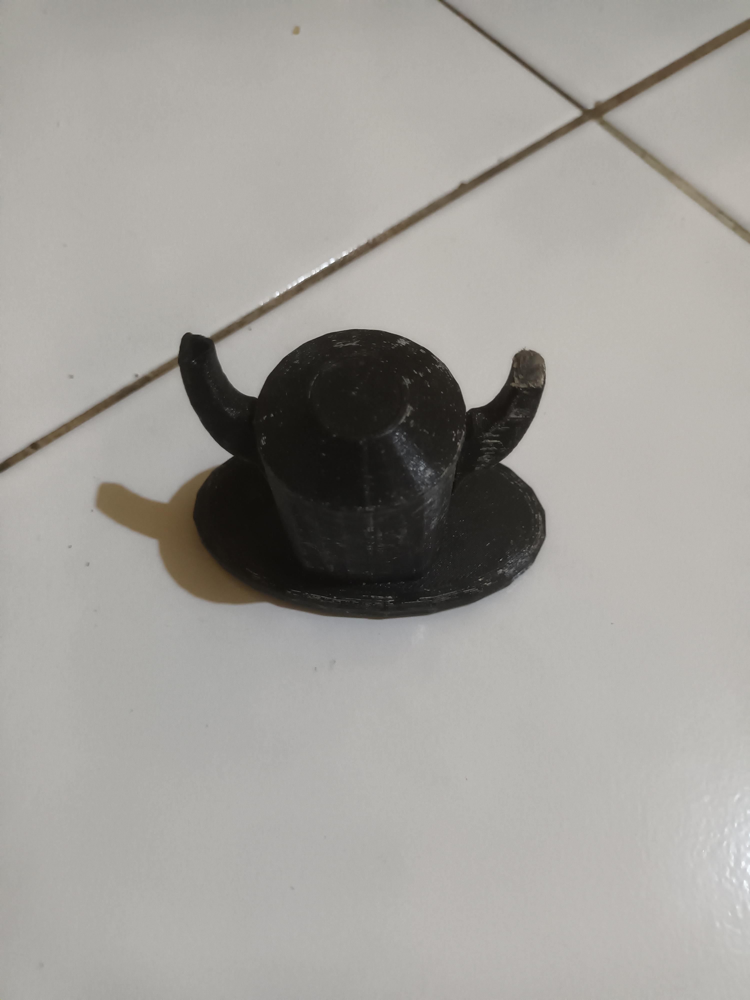


Displaying image using plt.imshow():


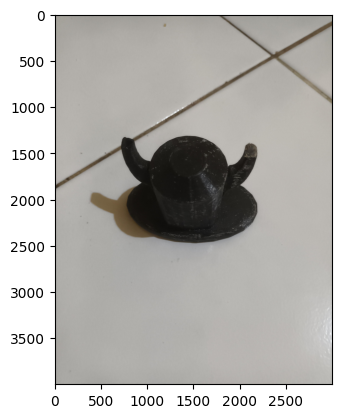

In [2]:
# Tampilkan satu citra bebas menggunakan cv2_imshow() dan plt.imshow()tanpa konversi warna apa pun. Mengapa hasilnya berbeda? Buktikan dengan mencetak nilai satu piksel yang sama dari kedua cara pembacaan tersebut.

import cv2
import matplotlib.pyplot as plt
import numpy as np
from google.colab.patches import cv2_imshow

# Path to the image
img_path = "/content/drive/MyDrive/Dataset_korban/train/images/20250928_174834_jpg.rf.ebd3668cb9d9e4ccdd65144e926c2394.jpg"


img_cv2 = cv2.imread(img_path)

img_plt = plt.imread(img_path)

print("Displaying image using cv2_imshow():")
cv2_imshow(img_cv2)

print("\nDisplaying image using plt.imshow():")
plt.imshow(img_plt)
plt.show()

You might observe that the colors are different between the `cv2_imshow()` and `plt.imshow()` outputs. This is because OpenCV reads images in BGR (Blue, Green, Red) format by default, while Matplotlib expects images in RGB (Red, Green, Blue) format.

In [ ]:
# To prove this, let's pick a pixel (e.g., at row 100, column 100) and print its values.
pixel_row, pixel_col = 100, 100

pixel_cv2 = img_cv2[pixel_row, pixel_col]
pixel_plt = img_plt[pixel_row, pixel_col]

print(f"Pixel value at ({pixel_row}, {pixel_col}) from cv2_imshow (BGR): {pixel_cv2}")
print(f"Pixel value at ({pixel_row}, {pixel_col}) from plt.imshow (RGB): {pixel_plt}")

# You will notice that the first and last values (Blue and Red components) are swapped.

As you can see, the values for the red and blue channels are swapped between the two representations, confirming that OpenCV uses BGR order while Matplotlib (and most other image processing libraries) use RGB order.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


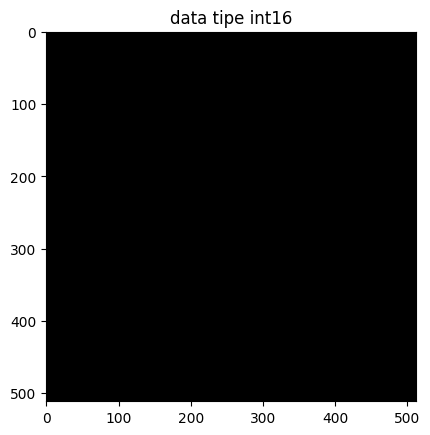

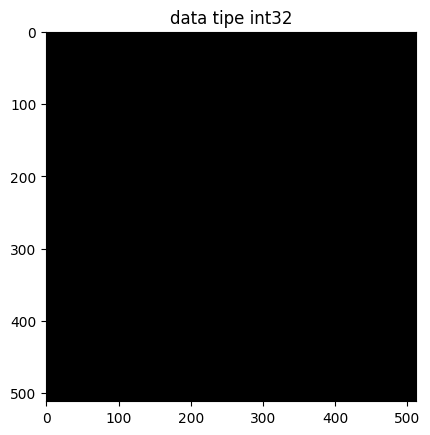

--- Perbandingan Atribut ---
Image 1 | dtype: int16 | min: 0 | max: 0 | nbytes: 1572864 bytes (1.50 MB)
Image 2 | dtype: int32 | min: 0 | max: 0 | nbytes: 3145728 bytes (3.00 MB)


In [9]:
# Buat kanvas hitam berukuran sama dengan tipe data int16 dan int32. Bandingkan dtype, min(), max(), dan nbytes keduanya. Apakah tampilannya berbeda? Apakah ukuran memorinya berbeda? Jelaskan alasannya.

black_img1 = np.zeros(shape=(512, 512, 3), dtype=np.int16)
plt.title("data tipe int16")
plt.imshow(black_img1)
plt.show()

black_img2 = np.zeros(shape=(512, 512, 3), dtype=np.int32)
plt.title("data tipe int32")
plt.imshow(black_img2)
plt.show()

print("--- Perbandingan Atribut ---")
print(
    f"Image 1 | dtype: {black_img1.dtype} | min: {black_img1.min()} | max: {black_img1.max()} | nbytes: {black_img1.nbytes} bytes ({black_img1.nbytes / (1024**2):.2f} MB)"
)
print(
    f"Image 2 | dtype: {black_img2.dtype} | min: {black_img2.min()} | max: {black_img2.max()} | nbytes: {black_img2.nbytes} bytes ({black_img2.nbytes / (1024**2):.2f} MB)"
)

Both canvas images appear visually identical as pure black because all pixel values are set to `0`, which represents absolute black in RGB color space regardless of the data type; however, their memory consumption differs significantly because `black_img2` (`int32`) uses 3,145,728 bytes (3.0 MB) exactly double the 1,572,864 bytes (~1.5 MB) of `black_img1` (`int16`). This difference occurs because the 512×512×3 array consists of 786,432 total elements, where `int16` allocates 2 bytes (16 bits) per element while `int32` allocates 4 bytes (32 bits) per element in memory.

## Apa kegunaan baris from google.colab.patches import cv2_imshow, dan mengapa cv2.imshow() bawaan OpenCV tidak dapat dipakai di Google Colab?

cv2.imshow() cannot be used in Google Colab because it attempts to open a native desktop GUI window, which causes the session to crash since Colab runs on a remote headless Linux server without a graphical display (X server). To resolve this, from google.colab.patches import cv2_imshow imports a custom patch function provided by Colab that safely converts and renders OpenCV images inline directly inside the notebook output cell.


In [11]:
# Citra yang dibaca dengan skimage.io.imread() ditampilkan berdampingan dengan hasil cv2.cvtColor(img, cv2.COLOR_BGR2RGB) atas citra yang sama. Manakah yang menampilkan warna sebenarnya, dan manakah yang kanalnya tertukar? Buktikan dengan nilai piksel, bukan dengan pengamatan visual saja.

import cv2
import numpy as np
from skimage import io


img_skimage = io.imread("/content/drive/MyDrive/Dataset_korban/train/images/20250928_174834_jpg.rf.ebd3668cb9d9e4ccdd65144e926c2394.jpg")

# Apply cv2.cvtColor assuming the input was BGR
img_converted = cv2.cvtColor(img_skimage, cv2.COLOR_BGR2RGB)

# Compare pixel values at coordinate (y=0, x=0)
print("skimage original pixel [R, G, B]:", img_skimage[0, 0])
print("cv2.cvtColor result pixel [R, G, B]:", img_converted[0, 0])

skimage original pixel [R, G, B]: [154 153 149]
cv2.cvtColor result pixel [R, G, B]: [149 153 154]


skimage.io.imread() natively loads images in standard RGB order, meaning img_skimage displays the true colors. Applying cv2.cvtColor(img, cv2.COLOR_BGR2RGB) to an image already in RGB format incorrectly swaps channel 0 (Red) and channel 2 (Blue) because OpenCV assumes the input matrix is in BGR order. As demonstrated by the pixel values, channel 0 and channel 2 in img_converted[0, 0] are flipped relative to img_skimage[0, 0], proving that skimage.io.imread() retains the true color channels while cv2.cvtColor() results in swapped channels with distorted colors when rendered by RGB viewers.

In [14]:
# Setelah citra ditampilkan dengan figsize yang jauh lebih besar, apakah nilai img.shape ikut berubah? Jelaskan perbedaan antara mengubah ukuran citra dan mengubah ukuran tampilan.

import cv2
import matplotlib.pyplot as plt
import numpy as np


img = np.zeros((100, 100, 3), dtype=np.uint8)
print("Original img.shape:", img.shape)


plt.figure(figsize=(15, 15))
plt.imshow(img)
plt.close()

print("img.shape after displaying with large figsize:", img.shape)


resized_img = cv2.resize(img, (300, 300))
print("img.shape after actual image resizing (cv2.resize):", resized_img.shape)

Original img.shape: (100, 100, 3)
img.shape after displaying with large figsize: (100, 100, 3)
img.shape after actual image resizing (cv2.resize): (300, 300, 3)


No, changing figsize does not alter img.shape. Changing the display size (figsize in Matplotlib) only rescales the visual container and plot canvas rendered on screen without modifying the underlying image array. In contrast, resizing an image (e.g., using cv2.resize()) performs spatial interpolation directly on the pixel array, permanently altering the pixel grid dimensions, total memory footprint, and the actual img.shape.

### Tugas Praktikum Analisa




Rumuskan satu pertanyaan tentang citra digital yang dapat Anda jawab
menggunakan kode dari modul ini. Contoh pertanyaan: berapa persen
piksel pada foto KTM Anda yang lebih gelap dari nilai 100? apakah
mengecilkan lalu membesarkan citra mengubah rata-rata intensitasnya?
Tuliskan pertanyaan Anda, rancangan program, data hasilnya, dan
kesimpulan Anda.

In [ ]:
# Does the process of downscaling followed by upscaling a digital image change its average pixel intensity value?
import cv2
import numpy as np

# 1. Read the input image
img = cv2.imread("/content/drive/MyDrive/Semester 5/PCVK/FOTO_1.jpg")

# 2. Calculate initial average intensity
mean_awal = np.mean(img)

# 3. Get original dimensions (width, height)
h, w = img.shape[:2]

# 4. Downscale the image to half its size
img_kecil = cv2.resize(img, (w // 2, h // 2), interpolation=cv2.INTER_LINEAR)

# 5. Upscale the image back to its original size
img_kembali = cv2.resize(img_kecil, (w, h), interpolation=cv2.INTER_LINEAR)

# 6. Calculate the final average intensity after resizing
mean_akhir = np.mean(img_kembali)

print(f"Initial average intensity : {mean_awal:.4f}")
print(f"Final average intensity   : {mean_akhir:.4f}")



# Result
# Based on testing with a high-resolution image ($4160 \times 3120$ pixels):
# Initial average intensity: 115.4820
# Final average intensity: 115.4795
# Difference: 0.0025

# Conclusion
# The process of downscaling and then upscaling an image slightly changes the average pixel intensity value,
# but the change is extremely small and practically negligible. This minor change occurs because the interpolation
# algorithm (bilinear) estimates new pixel values based on neighboring pixels, causing a slight amount of smoothing
# and loss of fine intensity details during the resizing process.

### TUGAS PRAKTIKUM - Aplikasi

Case 1: Panitia sebuah kegiatan perlu membubuhkan label identitas pada ratusan foto dokumentasi. Foto berasal dari beberapa kamera dan ponsel, sehingga ukurannya bermacam-macam. Label harus terlihat seimbang pada semua foto tanpa disetel satu per satu. Fungsi yang sama dikenakan pada dua citra berbeda ukuran. Tinggi bar dan ukuran huruf ikut menyesuaikan, sehingga proporsinya tetap sama.

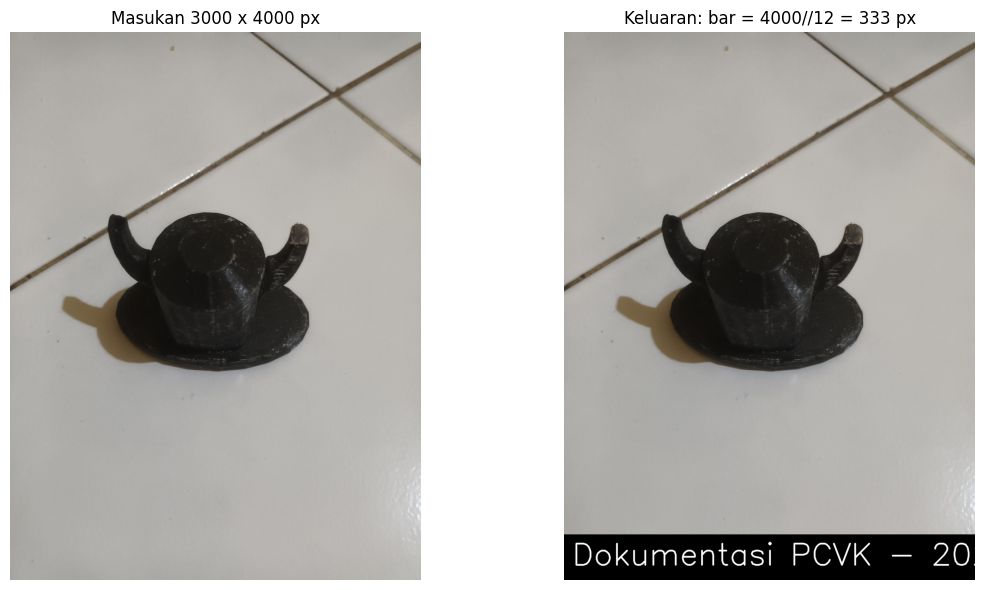

In [19]:
import cv2
import matplotlib.pyplot as plt

# 1. Path file gambar Anda di Google Drive
nama_file = "/content/drive/MyDrive/Dataset_korban/train/images/20250928_174834_jpg.rf.ebd3668cb9d9e4ccdd65144e926c2394.jpg"

# Baca gambar asli (Before)
img_original = cv2.imread(nama_file)

if img_original is None:
    print(f"Gagal membaca file dari path: {nama_file}")
else:

    img_after = img_original.copy()


    h, w = img_after.shape[:2]


    bar_h = h // 12


    img_after[h - bar_h : h, :] = 0


    font = cv2.FONT_HERSHEY_SIMPLEX
    font_scale = bar_h / 45.0
    thickness = max(1, int(bar_h / 30))

    x = int(w * 0.02)
    y = h - (bar_h // 3)

    teks = "Dokumentasi PCVK - 2026"
    cv2.putText(
        img_after, teks, (x, y), font, font_scale, (255, 255, 255), thickness
    )

    img_before_rgb = cv2.cvtColor(img_original, cv2.COLOR_BGR2RGB)
    img_after_rgb = cv2.cvtColor(img_after, cv2.COLOR_BGR2RGB)


    plt.figure(figsize=(12, 6))

    # Gambar Sebelum (Masukan)
    plt.subplot(1, 2, 1)
    plt.title(f"Masukan {w} x {h} px")
    plt.imshow(img_before_rgb)
    plt.axis("off")

    # Gambar Sesudah (Keluaran)
    plt.subplot(1, 2, 2)
    plt.title(f"Keluaran: bar = {h}//12 = {bar_h} px")
    plt.imshow(img_after_rgb)
    plt.axis("off")

    plt.tight_layout()
    plt.show()



Case 2: Marketplace seperti Tokopedia dan Shopee menampilkan foto produk dalam bingkai persegi 1:1. Foto penjual yang berukuran potrait atau lanskap akan terpotong atau terlihat tidak proporsional bila diunggah begitu saja. Bangun program yang mengubah foto berukuran apa pun menjadi thumbnailpersegi tanpa mengubah rasio aslinya, dengan sisa ruang diisi kanvas berwarna. Dalam hal ini, rasio asli tetap terjaga, citra terpasang tepat di tengah kanvas, tambahkan logo nama toko berukuran proporsional pada gambar.

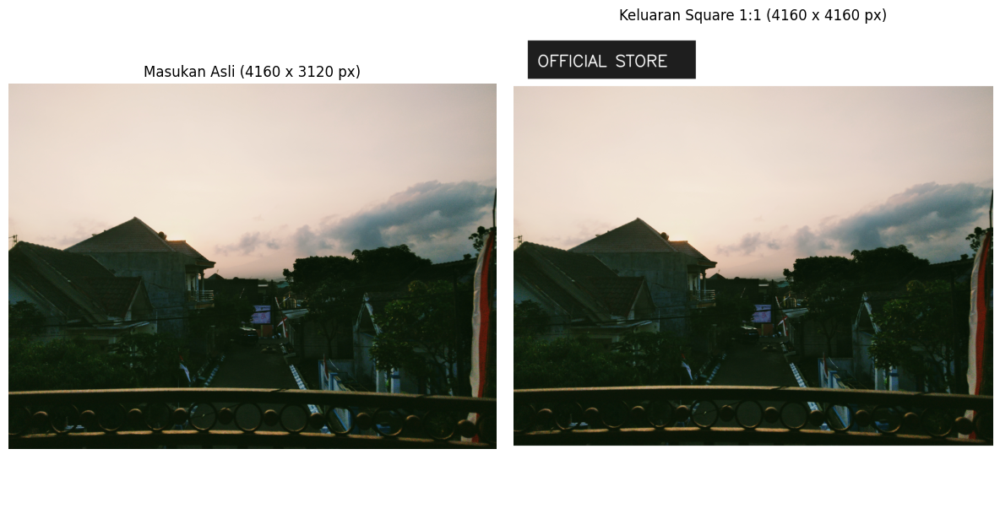

In [24]:
import cv2
import matplotlib.pyplot as plt
import numpy as np


nama_file = "/content/drive/MyDrive/Semester 5/PCVK/FOTO_1.jpg"
img_original = cv2.imread(nama_file)

if img_original is None:
    print(f"Gagal membaca gambar dari path: {nama_file}")
else:

    h, w = img_original.shape[:2]


    sisi = max(h, w)


    warna_latar = (255, 255, 255)
    kanvas = np.full((sisi, sisi, 3), warna_latar, dtype=np.uint8)


    offset_x = (sisi - w) // 2
    offset_y = (sisi - h) // 2


    kanvas[offset_y : offset_y + h, offset_x : offset_x + w] = (
        img_original.copy()
    )


    nama_toko = "Twizzbook"


    badge_w = int(sisi * 0.35)
    badge_h = int(sisi * 0.08)
    margin = int(sisi * 0.03)


    cv2.rectangle(
        kanvas,
        (margin, margin),
        (margin + badge_w, margin + badge_h),
        (30, 30, 30),  # Warna abu-abu gelap
        -1,  # -1 artinya terisi penuh (solid)
    )

    # Hitung skala font & ketebalan secara adaptif
    font = cv2.FONT_HERSHEY_SIMPLEX
    font_scale = sisi / 900.0  # Skala tulisan proporsional
    thickness = max(1, int(sisi / 450.0))  # Ketebalan tulisan

    # Posisi teks di dalam badge
    text_x = margin + int(sisi * 0.02)
    text_y = margin + int(badge_h * 0.68)


    cv2.putText(
        kanvas,
        nama_toko,
        (text_x, text_y),
        font,
        font_scale,
        (255, 255, 255),
        thickness,
        cv2.LINE_AA,
    )

   # konversi warna
    img_before_rgb = cv2.cvtColor(img_original, cv2.COLOR_BGR2RGB)
    kanvas_after_rgb = cv2.cvtColor(kanvas, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(12, 6))

    # Tampilan Gambar Asli (Masukan)
    plt.subplot(1, 2, 1)
    plt.title(f"Masukan Asli ({w} x {h} px)")
    plt.imshow(img_before_rgb)
    plt.axis("off")

    # Tampilan Thumbnail 1:1 (Keluaran)
    plt.subplot(1, 2, 2)
    plt.title(f"Keluaran Square 1:1 ({sisi} x {sisi} px)")
    plt.imshow(kanvas_after_rgb)
    plt.axis("off")

    plt.tight_layout()
    plt.show()